# Random forest, gradient boosting y evaluación final

Se usa la partición creada en `EDA.ipynb` (`data/processed/particion.csv`) y los mejores hiperparámetros encontrados en `Baselines_Arbol.ipynb`.

En este notebook:
1. Entrenamos dos modelos nuevos (random forest y gradient boosting) con búsqueda de hiperparámetros.
2. Comparamos los cinco modelos con la misma validación cruzada.
3. Evaluamos el mejor modelo **una sola vez** en el conjunto de prueba.
4. Analizamos sus errores, posibles sesgos y las limitaciones de los datos.

## Configuración

Igual que en `Baselines_Arbol.ipynb`: validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento. El conjunto de prueba se carga hasta la sección de evaluación final.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.metrics import (make_scorer, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
SEMILLA = 42

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_DATOS = RAIZ / "data" / "raw" / "diabetes_012_health_indicators_BRFSS2015.csv.zip"
RUTA_PARTICION = RAIZ / "data" / "processed" / "particion.csv"
DIR_RESULTADOS = RAIZ / "resultados"
DIR_FIGURAS = DIR_RESULTADOS / "figuras"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

OBJETIVO = "Diabetes_012"
NOMBRES_CLASE = {0: "Sin diabetes", 1: "Prediabetes", 2: "Diabetes"}
COLORES = ["#86b6ef", "#2a78d6", "#104281"]

In [2]:
df = pd.read_csv(RUTA_DATOS).astype(int)
particion = pd.read_csv(RUTA_PARTICION, index_col="indice")["conjunto"]
train = df[particion == "train"]

X_train = train.drop(columns=OBJETIVO)
y_train = train[OBJETIVO]
print(f"X_train: {X_train.shape}")

X_train: (202944, 21)


In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

METRICAS = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    # recall de cada clase por separado
    "recall_sin": make_scorer(recall_score, labels=[0], average="macro"),
    "recall_pre": make_scorer(recall_score, labels=[1], average="macro"),
    "recall_dia": make_scorer(recall_score, labels=[2], average="macro"),
}

resultados = {}  # métricas de validación cruzada de cada modelo


def metricas_modelo(modelo):
    # Validación cruzada de un modelo con hiperparámetros fijos
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=METRICAS,
                       return_train_score=True, n_jobs=-1)
    metricas = {m: r[f"test_{m}"].mean() for m in METRICAS}
    metricas["f1_macro_std"] = r["test_f1_macro"].std()
    metricas["f1_macro_train"] = r["train_f1_macro"].mean()
    return metricas


def metricas_busqueda(busqueda):
    # Métricas de validación cruzada del mejor modelo de una búsqueda
    i = busqueda.best_index_
    r = busqueda.cv_results_
    metricas = {m: r[f"mean_test_{m}"][i] for m in METRICAS}
    metricas["f1_macro_std"] = r["std_test_f1_macro"][i]
    metricas["f1_macro_train"] = r["mean_train_f1_macro"][i]
    return metricas


def tabla_busqueda(busqueda, n=5):
    # Las n mejores combinaciones de una búsqueda, con F1 en entrenamiento y validación
    r = pd.DataFrame(busqueda.cv_results_)
    columnas = [c for c in r.columns if c.startswith("param_")]
    tabla = r[columnas + ["mean_train_f1_macro", "mean_test_f1_macro", "mean_test_recall_pre"]]
    tabla.columns = [c.replace("param_", "") for c in columnas] + [
        "F1 macro train", "F1 macro validación", "Recall prediabetes"]
    return tabla.sort_values("F1 macro validación", ascending=False).head(n).round(4)

## Modelos de referencia

Volvemos a evaluar el baseline trivial, la regresión logística y el árbol de decisión con los mejores hiperparámetros de `Baselines_Arbol.ipynb` y con las mismas particiones, para tener los cinco modelos en una sola tabla. Agregamos el recall de cada clase, que no estaba en la tabla anterior.

In [4]:
logistica = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(C=0.01, class_weight="balanced", max_iter=2000)),
])
arbol = DecisionTreeClassifier(criterion="entropy", max_depth=None, min_samples_split=25,
                               min_samples_leaf=1, random_state=SEMILLA)

resultados["Baseline trivial"] = metricas_modelo(DummyClassifier(strategy="most_frequent"))
resultados["Regresión logística"] = metricas_modelo(logistica)
resultados["Árbol de decisión"] = metricas_modelo(arbol)
pd.DataFrame(resultados).T.round(3)

,accuracy,precision_macro,recall_macro,f1_macro,recall_sin,recall_pre,recall_dia,f1_macro_std,f1_macro_train
Baseline trivial,0.842,0.281,0.333,0.305,1.000,0.000,0.000,0.000,0.305
Regresión logística,0.645,0.446,0.517,0.427,0.662,0.299,0.590,0.001,0.427
Árbol de decisión,0.826,0.433,0.399,0.406,0.938,0.004,0.255,0.002,0.522


- Los valores coinciden con `Baselines_Arbol.ipynb`: baseline trivial 0.305, regresión logística 0.427 y árbol 0.406 de F1 macro.
- El recall por clase muestra lo que el F1 macro no deja ver: la regresión logística encuentra al 30% de las personas con prediabetes y al 59% de las personas con diabetes. El árbol solo encuentra al 0.4% y al 26%, porque casi siempre predice "sin diabetes" (recall de 0.94 en esa clase).

## Random forest

Un random forest promedia muchos árboles entrenados con muestras distintas de los datos y de las variables. Esto reduce el sobreajuste que vimos en el árbol individual.

Usamos 100 árboles y `max_samples=0.5` (cada árbol ve la mitad de los datos) para que la búsqueda termine en pocos minutos con 200 mil registros. Probamos 12 combinaciones al azar con `RandomizedSearchCV`:

- `max_depth`: profundidad máxima de cada árbol.
- `min_samples_leaf`: mínimo de registros en cada hoja.
- `max_features`: cuántas variables puede considerar cada división.
- `class_weight`: sin pesos, pesos balanceados o balanceados en cada muestra (`balanced_subsample`).

In [5]:
bosque = RandomForestClassifier(n_estimators=100, max_samples=0.5, n_jobs=1, random_state=SEMILLA)

parametros_bosque = {
    "max_depth": [10, 15, 20, 25],
    "min_samples_leaf": [1, 5, 10, 25, 50],
    "max_features": ["sqrt", 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

busqueda_bosque = RandomizedSearchCV(bosque, parametros_bosque, n_iter=12, cv=cv,
                                     scoring=METRICAS, refit="f1_macro", return_train_score=True,
                                     random_state=SEMILLA, n_jobs=-1)
busqueda_bosque.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_bosque.best_params_)
resultados["Random forest"] = metricas_busqueda(busqueda_bosque)
pd.Series(resultados["Random forest"]).round(3)

Mejores hiperparámetros: {'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 20, 'class_weight': 'balanced_subsample'}


accuracy           0.755
precision_macro    0.433
recall_macro       0.497
f1_macro           0.439
recall_sin         0.779
recall_pre         0.008
recall_dia         0.706
f1_macro_std       0.002
f1_macro_train     0.646
dtype: float64

In [6]:
tabla_busqueda(busqueda_bosque)

,min_samples_leaf,max_features,max_depth,class_weight,F1 macro train,F1 macro validación,Recall prediabetes
9,10,0.5,20,balanced_subsample,0.6464,0.4392,0.0076
3,1,0.5,15,balanced,0.6357,0.4346,0.0656
11,10,sqrt,20,balanced,0.5402,0.4293,0.1282
8,1,sqrt,10,balanced,0.4716,0.4286,0.1881
6,25,sqrt,25,balanced,0.4784,0.4262,0.2003


**Resultados:**
- Mejor configuración: `max_depth=20`, `min_samples_leaf=10`, `max_features=0.5` y `class_weight="balanced_subsample"`, con **F1 macro de 0.439**. Es el mejor valor hasta ahora: supera a la regresión logística (0.427) y al árbol (0.406). La desviación entre particiones es de solo 0.002, así que es poco probable que la diferencia con la logística sea ruido.
- Encuentra al 71% de las personas con diabetes (la logística encuentra al 59%), pero **casi nunca predice prediabetes** (recall de 0.008).
- La tabla muestra un patrón: los bosques más complejos (más profundos, más variables por división) suben el F1 macro pero dejan de detectar prediabetes. El bosque de profundidad 10 encuentra al 19% de las personas con prediabetes, con un F1 macro menor (0.429).
- Hay una brecha grande entre entrenamiento (0.646) y validación (0.439). En un random forest esto es esperado, porque cada árbol es profundo y casi memoriza su muestra; lo que importa es que el F1 de validación es el más alto y estable entre particiones.

## Gradient boosting

El gradient boosting entrena árboles pequeños uno tras otro, y cada árbol corrige los errores de los anteriores. Usamos `HistGradientBoostingClassifier` de scikit-learn, que agrupa los valores de cada variable en intervalos y es rápido con muchos registros.

No buscamos el número de árboles: lo fijamos alto (`max_iter=500`) y usamos **parada temprana**. El modelo aparta el 10% de cada partición de entrenamiento y se detiene cuando la pérdida en ese 10% deja de mejorar durante 20 iteraciones. Ese 10% es distinto de la partición de validación y del conjunto de prueba.

Probamos 15 combinaciones al azar:

- `learning_rate`: cuánto corrige cada árbol nuevo.
- `max_leaf_nodes`: tamaño de cada árbol.
- `min_samples_leaf`: mínimo de registros en cada hoja.
- `l2_regularization`: penalización que suaviza las predicciones.
- `class_weight`: con o sin pesos para las clases.

In [7]:
boosting = HistGradientBoostingClassifier(max_iter=500, early_stopping=True, validation_fraction=0.1,
                                          n_iter_no_change=20, random_state=SEMILLA)

parametros_boosting = {
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 1.0, 5.0],
    "class_weight": [None, "balanced"],
}

busqueda_boosting = RandomizedSearchCV(boosting, parametros_boosting, n_iter=15, cv=cv,
                                       scoring=METRICAS, refit="f1_macro", return_train_score=True,
                                       random_state=SEMILLA, n_jobs=-1)
busqueda_boosting.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_boosting.best_params_)
print("Árboles usados por la parada temprana:", busqueda_boosting.best_estimator_.n_iter_)
resultados["Gradient boosting"] = metricas_busqueda(busqueda_boosting)
pd.Series(resultados["Gradient boosting"]).round(3)

Mejores hiperparámetros: {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'learning_rate': 0.05, 'l2_regularization': 1.0, 'class_weight': 'balanced'}
Árboles usados por la parada temprana: 65


accuracy           0.632
precision_macro    0.442
recall_macro       0.520
f1_macro           0.422
recall_sin         0.638
recall_pre         0.275
recall_dia         0.646
f1_macro_std       0.001
f1_macro_train     0.449
dtype: float64

In [8]:
tabla_busqueda(busqueda_boosting)

,min_samples_leaf,max_leaf_nodes,learning_rate,l2_regularization,class_weight,F1 macro train,F1 macro validación,Recall prediabetes
10,20,63,0.05,1.0,balanced,0.4488,0.4217,0.2753
3,20,63,0.20,1.0,balanced,0.4616,0.4214,0.2521
8,50,63,0.10,5.0,balanced,0.4520,0.4208,0.2634
5,20,31,0.03,0.0,balanced,0.4354,0.4204,0.3023
1,20,63,0.20,5.0,balanced,0.4600,0.4201,0.2524


**Resultados:**
- Mejor configuración: `learning_rate=0.05`, `max_leaf_nodes=63`, `min_samples_leaf=20`, `l2_regularization=1.0` y `class_weight="balanced"`. La parada temprana se detuvo en 65 árboles.
- F1 macro de **0.422**, por debajo de la regresión logística (0.427) y del random forest (0.439).
- Las cinco mejores combinaciones usan pesos balanceados y quedan entre 0.420 y 0.422: el modelo llegó a un techo y cambiar los hiperparámetros casi no lo mueve.
- A diferencia del random forest, sí detecta prediabetes: encuentra al 28% de esas personas, casi igual que la regresión logística (30%).
- Casi no se sobreajusta: 0.449 en entrenamiento contra 0.422 en validación. La parada temprana evita que siga agregando árboles que solo memorizan.

## Comparación de modelos

Todos los valores son promedios de las 5 particiones de validación cruzada sobre el conjunto de entrenamiento. `brecha_f1` es la diferencia entre el F1 macro en entrenamiento y en validación: si es grande, el modelo se sobreajusta.

In [9]:
comparacion = pd.DataFrame(resultados).T
comparacion["brecha_f1"] = comparacion["f1_macro_train"] - comparacion["f1_macro"]
comparacion.round(3)

,accuracy,precision_macro,recall_macro,f1_macro,recall_sin,recall_pre,recall_dia,f1_macro_std,f1_macro_train,brecha_f1
Baseline trivial,0.842,0.281,0.333,0.305,1.000,0.000,0.000,0.000,0.305,0.000
Regresión logística,0.645,0.446,0.517,0.427,0.662,0.299,0.590,0.001,0.427,0.001
Árbol de decisión,0.826,0.433,0.399,0.406,0.938,0.004,0.255,0.002,0.522,0.115
Random forest,0.755,0.433,0.497,0.439,0.779,0.008,0.706,0.002,0.646,0.207
Gradient boosting,0.632,0.442,0.520,0.422,0.638,0.275,0.646,0.001,0.449,0.027


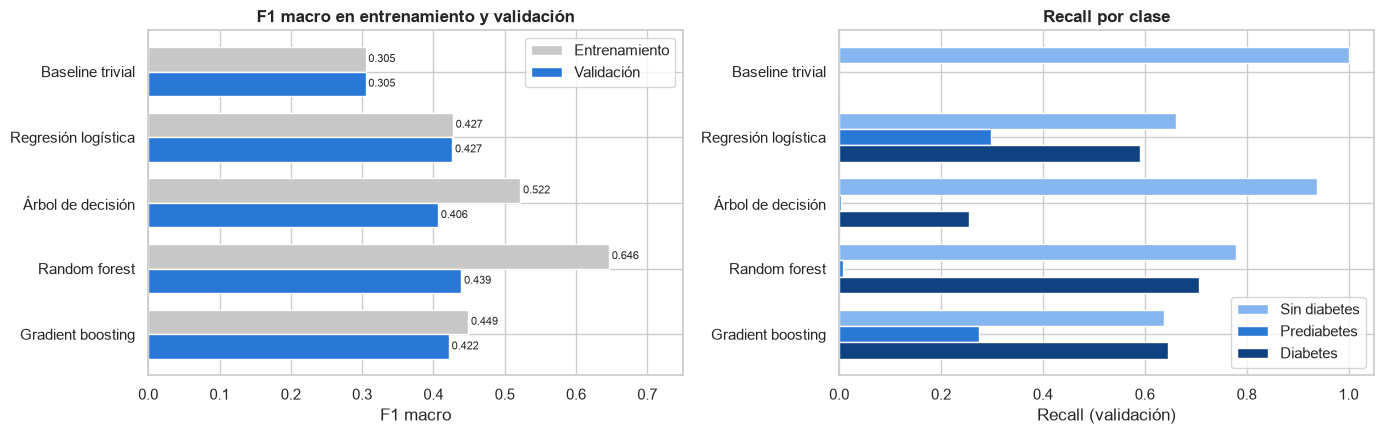

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

f1 = comparacion[["f1_macro_train", "f1_macro"]].rename(
    columns={"f1_macro_train": "Entrenamiento", "f1_macro": "Validación"})
f1.plot.barh(ax=ax1, color=["#c8c8c8", "#2a78d6"], width=0.75)
for contenedor in ax1.containers:
    ax1.bar_label(contenedor, fmt="%.3f", fontsize=8, padding=2)
ax1.invert_yaxis()
ax1.set_xlim(0, 0.75)
ax1.set_xlabel("F1 macro")
ax1.set_title("F1 macro en entrenamiento y validación", fontweight="bold")
ax1.legend(loc="upper right")

recall = comparacion[["recall_sin", "recall_pre", "recall_dia"]]
recall.columns = NOMBRES_CLASE.values()
recall.plot.barh(ax=ax2, color=COLORES, width=0.75)
ax2.invert_yaxis()
ax2.set_xlim(0, 1.05)
ax2.set_xlabel("Recall (validación)")
ax2.set_title("Recall por clase", fontweight="bold")
ax2.legend(loc="lower right")

fig.tight_layout()
fig.savefig(DIR_FIGURAS / "comparacion_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

**Qué muestra:** a la izquierda, el F1 macro de cada modelo en entrenamiento y en validación; a la derecha, qué proporción de cada clase encuentra cada modelo.

**Patrón:**
- Todos los modelos superan al baseline trivial (0.305). El mejor es el random forest (0.439), seguido de la regresión logística (0.427), el gradient boosting (0.422) y el árbol (0.406). Las diferencias entre los modelos útiles son pequeñas (0.03 de F1 macro): con estas 21 variables de encuesta hay un techo cercano a 0.44.
- **Sobreajuste:** la regresión logística (brecha 0.001) y el gradient boosting (0.027) generalizan casi igual de bien que en entrenamiento. El árbol (0.115) y el random forest (0.207) tienen brechas grandes, porque sus árboles son profundos.
- **Prediabetes:** hay dos grupos de modelos. La logística y el gradient boosting encuentran al 28-30% de la prediabetes; el árbol y el random forest casi nunca la predicen. El F1 macro premia más el mejor desempeño del random forest en "sin diabetes" y "diabetes" que lo que pierde en prediabetes.

**Decisión:** elegimos el modelo con mayor F1 macro, como definimos en la propuesta. La regla se fija antes de ver el conjunto de prueba, para que la evaluación final no influya en la elección.

### Elección del modelo final

Elegimos el modelo con mayor F1 macro en validación, que es la métrica principal del proyecto. Las búsquedas ya re-entrenaron su mejor modelo con todo el conjunto de entrenamiento; la regresión logística y el árbol se entrenan aquí.

In [11]:
modelos = {
    "Regresión logística": logistica.fit(X_train, y_train),
    "Árbol de decisión": arbol.fit(X_train, y_train),
    "Random forest": busqueda_bosque.best_estimator_,
    "Gradient boosting": busqueda_boosting.best_estimator_,
}

nombre_mejor = comparacion.drop("Baseline trivial")["f1_macro"].idxmax()
mejor_modelo = modelos[nombre_mejor]
print(f"Modelo final: {nombre_mejor}  (F1 macro validación {comparacion.loc[nombre_mejor, 'f1_macro']:.3f})")

Modelo final: Random forest  (F1 macro validación 0.439)


## Evaluación final en el conjunto de prueba

Esta es la **única vez** que se usa el conjunto de prueba. Solo evaluamos el modelo final; el baseline trivial se muestra como referencia.

In [12]:
test = df[particion == "test"]
X_test = test.drop(columns=OBJETIVO)
y_test = test[OBJETIVO]

pred_test = mejor_modelo.predict(X_test)
proba_test = mejor_modelo.predict_proba(X_test)

f1_test = f1_score(y_test, pred_test, average="macro")
f1_baseline_test = f1_score(y_test, np.zeros_like(y_test), average="macro")
print(f"F1 macro en prueba:             {f1_test:.3f}")
print(f"F1 macro en validación cruzada: {comparacion.loc[nombre_mejor, 'f1_macro']:.3f}")
print(f"Baseline trivial en prueba:     {f1_baseline_test:.3f}\n")
print(classification_report(y_test, pred_test, target_names=NOMBRES_CLASE.values(), digits=3))

F1 macro en prueba:             0.438
F1 macro en validación cruzada: 0.439
Baseline trivial en prueba:     0.305

              precision    recall  f1-score   support

Sin diabetes      0.931     0.779     0.848     42741
 Prediabetes      0.030     0.008     0.012       926
    Diabetes      0.336     0.699     0.453      7069

    accuracy                          0.754     50736
   macro avg      0.432     0.495     0.438     50736
weighted avg      0.831     0.754     0.778     50736



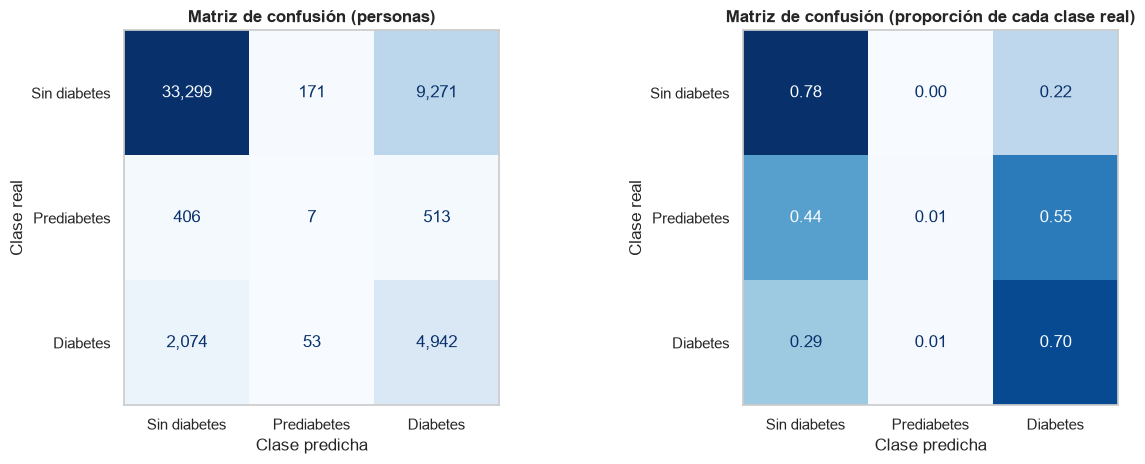

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
etiquetas = list(NOMBRES_CLASE.values())

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=etiquetas).plot(
    ax=ax1, cmap="Blues", colorbar=False, values_format=",")
ax1.set_title("Matriz de confusión (personas)", fontweight="bold")

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test, normalize="true"), display_labels=etiquetas).plot(
    ax=ax2, cmap="Blues", colorbar=False, values_format=".2f")
ax2.set_title("Matriz de confusión (proporción de cada clase real)", fontweight="bold")

for ax in (ax1, ax2):
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.grid(False)

fig.tight_layout()
fig.savefig(DIR_FIGURAS / "matriz_confusion_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Resultados en prueba:**
- F1 macro de **0.438**, prácticamente igual al de validación cruzada (0.439) y muy por encima del baseline trivial (0.305). La validación cruzada fue una buena estimación y el modelo no se sobreajustó a los datos de entrenamiento, a pesar de la brecha que vimos antes.
- La clase se decide con la probabilidad más alta del modelo (sin ajustar umbrales), con los pesos `balanced_subsample` que eligió la búsqueda.
- **Diabetes:** encuentra a 4,942 de las 7,069 personas con diabetes (recall 0.70) y no detecta a 2,074 (29%).
- **Falsas alarmas:** 9,271 personas sin diabetes (22% de esa clase) son marcadas como diabetes. Por eso, de las 14,726 personas que el modelo marca como "diabetes", solo el 34% la tiene; si contamos a las 513 con prediabetes, que también se beneficiarían de una prueba médica, el 37% tiene alguna de las dos.
- **Prediabetes:** solo acierta 7 de 926 casos (recall 0.008). El 55% de las personas con prediabetes queda como "diabetes" y el 44% como "sin diabetes".
- El accuracy (75%) es menor que el del baseline (84%), pero el baseline no detecta a ninguna persona enferma.

## Análisis de errores

Nos enfocamos en los dos errores más importantes para el problema:

- **Diabetes no detectada:** personas con diabetes que el modelo clasifica como "sin diabetes". Es el error más costoso, porque esa persona no recibiría la recomendación de hacerse una prueba.
- **Falsa alarma:** personas sin diabetes que el modelo clasifica como "diabetes". Cuesta menos (una prueba médica de más), pero si son demasiadas el modelo pierde utilidad.

Comparamos el perfil promedio de cada grupo con el de los aciertos.

In [14]:
analisis = X_test.copy()
analisis["real"] = y_test
analisis["predicho"] = pred_test
analisis["P(sin diabetes)"] = proba_test[:, 0]
analisis["P(diabetes)"] = proba_test[:, 2]

real, pred = analisis["real"], analisis["predicho"]
grupos = {
    "Diabetes detectada": (real == 2) & (pred == 2),
    "Diabetes no detectada": (real == 2) & (pred == 0),
    "Sin diabetes, acierto": (real == 0) & (pred == 0),
    "Falsa alarma": (real == 0) & (pred == 2),
}

VARIABLES_CLAVE = ["HighBP", "HighChol", "BMI", "GenHlth", "Age", "DiffWalk",
                   "HeartDiseaseorAttack", "PhysActivity", "Income"]
perfil = pd.DataFrame({nombre: analisis.loc[m, VARIABLES_CLAVE].mean() for nombre, m in grupos.items()}).T
perfil.insert(0, "personas", [m.sum() for m in grupos.values()])
perfil.round(2)

,personas,HighBP,HighChol,BMI,GenHlth,Age,DiffWalk,HeartDiseaseorAttack,PhysActivity,Income
Diabetes detectada,4942,0.88,0.77,33.39,3.61,9.62,0.47,0.28,0.57,4.85
Diabetes no detectada,2074,0.43,0.44,27.92,2.54,8.80,0.14,0.08,0.76,6.07
"Sin diabetes, acierto",33299,0.24,0.29,26.62,2.10,7.25,0.07,0.03,0.82,6.50
Falsa alarma,9271,0.84,0.70,31.66,3.38,9.62,0.37,0.21,0.63,5.19


**Qué muestra:** el promedio de las variables más importantes en cada grupo (en las binarias, el promedio es la proporción de personas que responde "sí").

**Patrón:**
- Las personas con **diabetes no detectada** se parecen mucho más a las personas sanas que a las personas con diabetes detectada: el 43% tiene presión alta (88% en las detectadas), su IMC promedio es 27.9 (33.4 en las detectadas), califican mejor su salud (2.5 contra 3.6) y tienen más ingreso.
- Las **falsas alarmas** tienen el perfil contrario: el 84% tiene presión alta, IMC de 31.7, peor salud general (3.4) y la misma edad promedio que las personas con diabetes detectada.

**Por qué:** el modelo aprendió a reconocer un **perfil de riesgo** (presión alta, colesterol, sobrepeso, mala salud, edad), no la diabetes en sí. Una persona con diabetes y perfil sano no tiene nada en estas 21 variables que la distinga de una persona sana, y una persona con perfil de riesgo y sin diagnóstico es igual a una persona con diabetes.

In [15]:
columnas_ejemplo = VARIABLES_CLAVE + ["P(sin diabetes)", "P(diabetes)"]

print("Personas con diabetes que el modelo descarta con más seguridad:")
no_detectados = analisis[grupos["Diabetes no detectada"]].sort_values("P(sin diabetes)", ascending=False)
display(no_detectados[columnas_ejemplo].head(5).round(2))

print("Personas sin diabetes que el modelo marca como diabetes con más seguridad:")
falsas_alarmas = analisis[grupos["Falsa alarma"]].sort_values("P(diabetes)", ascending=False)
display(falsas_alarmas[columnas_ejemplo].head(5).round(2))

Personas con diabetes que el modelo descarta con más seguridad:


,HighBP,HighChol,BMI,GenHlth,Age,DiffWalk,HeartDiseaseorAttack,PhysActivity,Income,P(sin diabetes),P(diabetes)
23247,0,0,25,1,5,0,0,1,8,1.0,0.0
220269,0,0,20,1,2,0,0,1,7,1.0,0.0
17997,0,0,23,1,5,0,0,1,8,1.0,0.0
76610,0,0,25,2,2,0,0,1,8,1.0,0.0
242144,0,0,21,2,2,0,0,1,7,1.0,0.0


Personas sin diabetes que el modelo marca como diabetes con más seguridad:


,HighBP,HighChol,BMI,GenHlth,Age,DiffWalk,HeartDiseaseorAttack,PhysActivity,Income,P(sin diabetes),P(diabetes)
98420,1,1,50,4,11,1,0,0,6,0.07,0.89
113430,1,1,39,5,10,1,1,0,3,0.07,0.88
101859,1,1,58,5,10,1,1,0,2,0.09,0.87
131225,1,1,56,5,8,1,0,0,5,0.07,0.87
4722,1,1,50,5,8,1,1,0,1,0.08,0.87


**Ejemplos concretos:**
- Las cinco personas con diabetes que el modelo descarta con más seguridad (probabilidad de "sin diabetes" cercana a 1) tienen entre 25 y 44 años, no tienen presión ni colesterol alto, tienen IMC entre 20 y 25, califican su salud como excelente o muy buena, hacen actividad física y tienen ingresos altos. Una explicación posible es que sean casos de **diabetes tipo 1**, que aparece en personas jóvenes y sin sobrepeso; la encuesta no distingue entre tipos de diabetes. Otra es que sean personas con diabetes bien controlada.
- Las cinco falsas alarmas más seguras (probabilidad de diabetes de 0.87 a 0.89) tienen presión y colesterol alto, IMC entre 39 y 58, salud regular o mala, dificultad para caminar y 55 años o más; tres tienen enfermedad del corazón. Una explicación posible es que algunas tengan **diabetes sin diagnosticar**: la etiqueta viene de lo que la persona reporta, así que alguien con diabetes que no ha ido al médico aparece como "sin diabetes".

### Prediabetes

La prediabetes es la clase más difícil. Revisamos a qué clases van las personas con prediabetes y qué tan distinto es su perfil del de las otras dos clases.

In [16]:
pre = analisis[real == 1]
print("Predicción para las personas con prediabetes:")
print(pre["predicho"].map(NOMBRES_CLASE).value_counts(normalize=True).round(3), "\n")

perfil_clase = analisis.groupby(real.map(NOMBRES_CLASE))[VARIABLES_CLAVE].mean()
perfil_clase.loc[etiquetas].round(2)

Predicción para las personas con prediabetes:
predicho
Diabetes        0.554
Sin diabetes    0.438
Prediabetes     0.008
Name: proportion, dtype: float64 



,HighBP,HighChol,BMI,GenHlth,Age,DiffWalk,HeartDiseaseorAttack,PhysActivity,Income
real,,,,,,,,,
Sin diabetes,0.37,0.38,27.73,2.38,7.77,0.13,0.07,0.78,6.21
Prediabetes,0.64,0.61,30.89,2.96,9.07,0.28,0.14,0.67,5.32
Diabetes,0.75,0.67,31.77,3.29,9.38,0.37,0.22,0.63,5.22


**Patrón:**
- El modelo final casi nunca predice prediabetes: el 55% de esas personas queda como "diabetes" y el 44% como "sin diabetes".
- En todas las variables, la prediabetes queda **entre** las otras dos clases y más cerca de la diabetes: presión alta en el 64% (37% sin diabetes, 75% diabetes), IMC de 30.9 (27.7 y 31.8), edad promedio de 9.1 (7.8 y 9.4).

**Por qué:** como la prediabetes está en medio, su probabilidad casi nunca es la más alta: cada persona con prediabetes se parece más a una de las otras dos clases. Además es solo el 1.8% de los datos, y es la etiqueta menos confiable, porque la mayoría de las personas con prediabetes no sabe que la tiene.

### Desempeño por subgrupos (posibles sesgos)

Revisamos si el modelo funciona igual para distintos grupos de sexo, edad e ingreso. Una diferencia grande indicaría que el modelo (o los datos) favorece a un grupo.

In [17]:
def desempeno_por_grupo(segmentos):
    # Métricas del modelo final en prueba para cada segmento de personas
    filas = {}
    for nombre, mascara in segmentos.items():
        y_r, y_p = y_test[mascara], pred_test[mascara.to_numpy()]
        filas[nombre] = {
            "personas": int(mascara.sum()),
            "% con diabetes": (y_r == 2).mean() * 100,
            "recall diabetes": recall_score(y_r, y_p, labels=[2], average="macro"),
            "recall prediabetes": recall_score(y_r, y_p, labels=[1], average="macro"),
            "F1 macro": f1_score(y_r, y_p, average="macro"),
        }
    return pd.DataFrame(filas).T


segmentos = {
    "Mujeres": X_test["Sex"] == 0,
    "Hombres": X_test["Sex"] == 1,
    "Edad 18-44": X_test["Age"] <= 5,
    "Edad 45-64": X_test["Age"].between(6, 9),
    "Edad 65+": X_test["Age"] >= 10,
    "Ingreso < $25k": X_test["Income"] <= 4,
    "Ingreso $25k-50k": X_test["Income"].between(5, 6),
    "Ingreso > $50k": X_test["Income"] >= 7,
}
desempeno_por_grupo(segmentos).round(3)

,personas,% con diabetes,recall diabetes,recall prediabetes,F1 macro
Mujeres,28209.0,13.003,0.702,0.010,0.443
Hombres,22527.0,15.097,0.696,0.005,0.432
Edad 18-44,10926.0,4.027,0.398,0.011,0.441
Edad 45-64,22129.0,13.358,0.688,0.005,0.438
Edad 65+,17681.0,20.774,0.744,0.009,0.405
Ingreso < $25k,11491.0,22.792,0.824,0.006,0.415
Ingreso $25k-50k,12483.0,15.341,0.710,0.015,0.427
Ingreso > $50k,26762.0,9.472,0.562,0.003,0.433


**Patrón:**
- **Sexo:** sin diferencias importantes (recall de diabetes de 0.70 en mujeres y hombres).
- **Edad:** el modelo encuentra solo al 40% de las personas de 18 a 44 años con diabetes, contra el 69% (45 a 64 años) y el 74% (65 o más).
- **Ingreso:** encuentra al 82% de las personas con diabetes de ingreso bajo, pero solo al 56% de las de ingreso mayor a $50k.

**Por qué:** las personas jóvenes y de mayor ingreso con diabetes tienen, en promedio, un perfil más sano (es el mismo patrón de los errores anteriores), y el modelo asocia la diabetes con edad alta y peor salud. Si se usara para decidir a quién recomendar una prueba, **recomendaría menos pruebas a personas jóvenes y de ingresos altos que sí tienen diabetes**. Es un sesgo que hay que reportar aunque el F1 macro por grupo sea parecido (entre 0.40 y 0.44).

### Importancia de las variables

Usamos importancia por permutación sobre una muestra de 15,000 personas del conjunto de prueba: se desordena una variable a la vez y se mide cuánto baja el F1 macro. A diferencia de la importancia interna de los árboles, se calcula con datos que el modelo no vio y no favorece a las variables con muchos valores distintos.

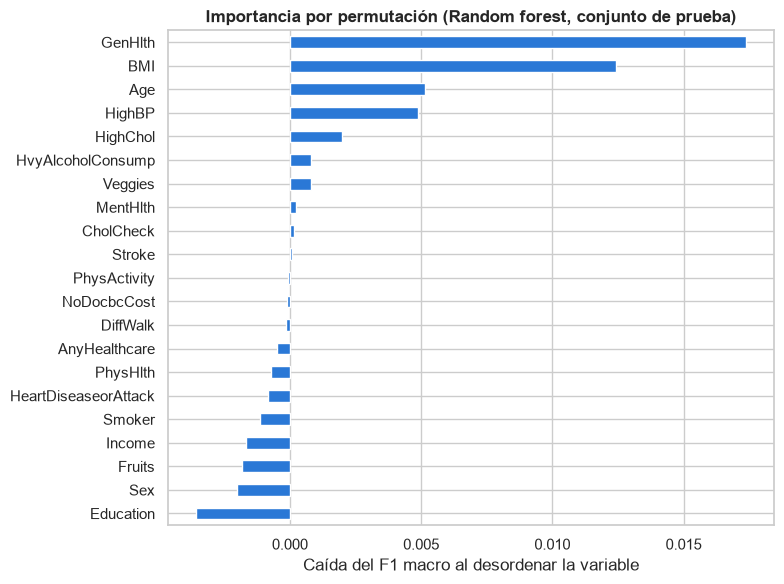

GenHlth              0.0174
BMI                  0.0124
Age                  0.0051
HighBP               0.0049
HighChol             0.0020
HvyAlcoholConsump    0.0008
Veggies              0.0008
MentHlth             0.0002
CholCheck            0.0001
Stroke               0.0001
dtype: float64

In [18]:
muestra = X_test.sample(15000, random_state=SEMILLA)
permutacion = permutation_importance(mejor_modelo, muestra, y_test.loc[muestra.index],
                                     scoring="f1_macro", n_repeats=5,
                                     random_state=SEMILLA, n_jobs=-1)
importancia = pd.Series(permutacion.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
importancia.plot.barh(ax=ax, color="#2a78d6")
ax.set_xlabel("Caída del F1 macro al desordenar la variable")
ax.set_title(f"Importancia por permutación ({nombre_mejor}, conjunto de prueba)", fontweight="bold")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "importancia_permutacion.png", dpi=150, bbox_inches="tight")
plt.show()

importancia.sort_values(ascending=False).head(10).round(4)

- Las variables que más pesan en el random forest son salud general (`GenHlth`), IMC (`BMI`), edad (`Age`), presión alta (`HighBP`) y colesterol alto (`HighChol`). Son las mismas que tenían mayor correlación con la diabetes en el EDA.
- Las demás variables tienen importancia cercana a cero. Esto no significa que no se relacionen con la diabetes: muchas están correlacionadas entre sí (por ejemplo, `DiffWalk` con `GenHlth`), y cuando se desordena una, el modelo usa la otra.
- La importancia mide cuánto usa el modelo cada variable para predecir, **no el efecto** de cambiarla. Con datos de encuesta de un solo momento no podemos decir que bajar el IMC reduzca la diabetes, solo que están asociados.

## Resultados guardados

Se guardan los hiperparámetros y la tabla de resultados en `resultados/`, igual que en `Baselines_Arbol.ipynb`.

In [19]:
mejores_hiperparametros = {
    "random_forest": busqueda_bosque.best_params_,
    "gradient_boosting": busqueda_boosting.best_params_,
    "modelo_final": nombre_mejor,
    "f1_macro_test": round(float(f1_test), 4),
}
with open(DIR_RESULTADOS / "mejores_hiperparametros_integrante2.json", "w") as f:
    json.dump(mejores_hiperparametros, f, indent=2)

comparacion.round(4).to_csv(DIR_RESULTADOS / "resultados_integrante2.csv")
print(json.dumps(mejores_hiperparametros, indent=2))

{
  "random_forest": {
    "min_samples_leaf": 10,
    "max_features": 0.5,
    "max_depth": 20,
    "class_weight": "balanced_subsample"
  },
  "gradient_boosting": {
    "min_samples_leaf": 20,
    "max_leaf_nodes": 63,
    "learning_rate": 0.05,
    "l2_regularization": 1.0,
    "class_weight": "balanced"
  },
  "modelo_final": "Random forest",
  "f1_macro_test": 0.4379
}


## Conclusiones y limitaciones

**Hallazgos:**
1. El **random forest** es el mejor modelo según la métrica principal: F1 macro de 0.439 en validación cruzada y **0.438 en prueba**, contra 0.305 del baseline trivial y 0.427 de la regresión logística.
2. Encuentra al **70% de las personas con diabetes** en prueba, a cambio de marcar como "diabetes" al 22% de las personas sanas.
3. **Ningún modelo resuelve la prediabetes.** El random forest prácticamente no la predice (recall 0.008). La regresión logística y el gradient boosting encuentran al 28-30%, con F1 macro un poco menor (0.427 y 0.422). Si el objetivo fuera detectar prediabetes, convendría la regresión logística: es casi igual de buena, no se sobreajusta y se puede interpretar. Esto muestra una limitación de elegir solo con el F1 macro. No cambiamos el modelo final después de ver el conjunto de prueba, porque eso sería usarlo dos veces.
4. El modelo aprendió un perfil de riesgo (salud general, IMC, edad, presión alta, colesterol). Falla con personas con diabetes y perfil sano (jóvenes, peso normal, sin hipertensión) y da falsas alarmas en personas con perfil de riesgo sin diagnóstico.

**Limitaciones y sesgos de los datos:**
- **Etiqueta autorreportada:** "sin diabetes" incluye a personas con diabetes o prediabetes que no han sido diagnosticadas. Algunas falsas alarmas podrían ser casos reales, y la etiqueta de prediabetes es la menos confiable.
- **Sin mediciones clínicas:** el diagnóstico real se hace con glucosa o hemoglobina glicosilada, que no están en la encuesta. Con solo hábitos y condiciones generales hay un techo de desempeño (cerca de 0.44 de F1 macro en todos los modelos).
- **No distingue el tipo de diabetes:** tipo 1 y tipo 2 están en la misma clase, y tienen perfiles distintos. La diabetes gestacional se cuenta como "sin diabetes".
- **Población:** adultos de Estados Unidos en 2015, encuestados por teléfono. Quedan fuera personas sin teléfono o que no respondieron, y los resultados no se pueden trasladar directamente a Guatemala.
- **Variables gruesas:** casi todas son de sí/no o rangos (edad en grupos de 5 años, ingreso en 8 niveles), y el IMC se calcula con peso y estatura reportados por la persona.
- **Duplicados:** conservamos el 9.4% de filas repetidas; algunas pueden quedar en entrenamiento y en prueba, lo que puede inflar un poco el resultado en la clase "sin diabetes".
- **Sesgo por subgrupos:** el modelo detecta menos diabetes en personas de 18 a 44 años (40%) y de ingresos altos (56%).
- **Búsqueda limitada:** por tiempo de cómputo probamos 12 combinaciones del random forest y 15 del gradient boosting, y no ajustamos umbrales por clase.

**Siguientes pasos:** ajustar umbrales de decisión por clase con validación cruzada para mejorar la prediabetes, probar un enfoque en dos etapas (sano contra no sano, luego prediabetes contra diabetes) y, si se tuviera acceso, agregar variables clínicas.